# RIN - experiment 7c: conjunctive cue-overlap retrieval

This notebook follows experiments 7b.1 and 7b.2.

7b showed that controlled sources are necessary, but also that improving cue
quality alone is not enough: denominator families still tied repeatedly.

So 7c changes the object under test. Instead of asking only how to normalize a
single aggregate field, it compares two ways of *building* the retrieval field:

- sum-based cue aggregation;
- conjunctive / overlap-based cue aggregation.

PageRank remains as an optional anti-hub correction on top of both.


In [1]:
import sys
from pathlib import Path


def find_repo_root(marker="requirements.txt"):
    path = Path.cwd()
    for candidate in [path, *path.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"could not find repo root (looked for {marker})")


REPO_ROOT = find_repo_root()
SRC = REPO_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("Repo root:", REPO_ROOT)


Repo root: c:\Users\yaros\BlackSabbitch_repo\RIN


In [2]:
from __future__ import annotations

from collections import Counter
import math
import re

import numpy as np

from embryonic import conceptnet_source
from embryonic.loader import EmbryonicGraphLoader
from embryonic.numberbatch import Numberbatch
from memory.diffuse import diffuse
from memory.graph import MemoryGraph
from memory.pagerank import in_strength_prior, weighted_in_strengths, weighted_out_strengths, weighted_pagerank

try:
    import matplotlib.pyplot as plt
except Exception:
    plt = None

try:
    import pandas as pd
except Exception:
    pd = None


In [3]:
SOURCE_DIR = REPO_ROOT / "source"

CONCEPTNET_DUMP = SOURCE_DIR / "conceptnet-assertions-5.7.0.csv.gz"
ATOMIC_CSV = SOURCE_DIR / "v4_atomic_all_agg.csv"
NUMBERBATCH_FILE = SOURCE_DIR / "numberbatch-en-19.08.txt.gz"

LANGUAGE = "en"
CONCEPTNET_BACKEND = "local_dump"
ATOMIC_FUZZY_LINKING = False
MIN_RELATED_TO_WEIGHT = 2.0

SEED_ENTRIES = [
    "coffee", "caffeine", "beverage", "energy", "water",
    "passport", "boarding pass", "check in", "airport", "travel", "hotel",
    "laptop", "charger", "office",
    "apartment", "wallet", "keys", "cats",
    "umbrella", "outdoor gear",
    "breakfast", "wake up", "espresso",
]

BASE_RADIUS = 3
LIMIT_PER_NODE = 30
MAX_NODES = 10_000

SOURCE_AMPLITUDE = 100.0
EXCLUDE_SOURCE_NODES = True
EPSILON = 1e-6
PAGERANK_ETA = 0.25
RUN_OPTIONAL_F4 = False

DIFFUSE_KW = {
    "decay": 0.8,
    "min_propagate_fraction": 0.01,
    "max_steps": 20,
}

TERM_VARIANTS = {
    "coffee": ["coffee"],
    "stimulant": ["stimulant"],
    "wake up": ["wake up", "wake_up"],
    "check in counter": ["check in counter", "checking in", "check in"],
    "document": ["document", "paper", "papers"],
    "identification": ["identification", "id", "identity card", "passport"],
    "laptop": ["laptop"],
    "plug": ["plug", "power plug", "electrical plug"],
    "outlet": ["outlet", "wall socket", "socket"],
    "battery": ["battery", "laptop battery"],
    "electricity": ["electricity"],
    "door": ["door", "front door"],
    "pocket": ["pocket", "coat pocket", "pants pocket"],
    "leave home": ["leave home", "go out", "going out"],
    "carry": ["carry", "bring", "take"],
    "tired": ["tired", "sleepy", "fatigue"],
    "alert": ["alert", "awake"],
    "neighbors": ["neighbors", "neighbour", "neighbor"],
    "rent": ["rent", "rental payment"],
    "dwelling": ["dwelling", "home", "residence"],
    "rooms": ["rooms", "room"],
    "itinerary": ["itinerary", "travel plan"],
    "route": ["route", "trip route", "path"],
    "hotel": ["hotel"],
    "pack suitcase": ["pack suitcase", "suitcase"],
    "travel": ["travel", "travel planning", "trip"],
    "trip": ["trip", "travel", "travel planning"],
}

GRAPH_VARIANTS = [
    {"name": "concept_only", "label": "ConceptNet only", "include_atomic": False},
    {"name": "concept_plus_atomic", "label": "ConceptNet + ATOMIC", "include_atomic": True},
]

METHODS = [
    {"name": "F0_sum_raw", "label": "F0 sum aggregation", "kind": "sum_raw"},
    {"name": "F1_sum_pagerank", "label": "F1 sum + PageRank^0.25", "kind": "sum_pagerank", "eta": PAGERANK_ETA},
    {"name": "F2_overlap_geom", "label": "F2 geometric overlap", "kind": "overlap_geom", "eps": EPSILON},
    {"name": "F3_overlap_geom_pagerank", "label": "F3 geometric overlap + PageRank^0.25", "kind": "overlap_geom_pagerank", "eps": EPSILON, "eta": PAGERANK_ETA},
]

if RUN_OPTIONAL_F4:
    METHODS.append({"name": "F4_overlap_geom_local_pagerank", "label": "F4 overlap + local leak + PageRank^0.25", "kind": "overlap_geom_local_pagerank", "eps": EPSILON, "eta": PAGERANK_ETA, "alpha": 1.0, "beta": 0.05, "gamma": 0.5})


In [4]:
QUERY_SPECS = [
    {
        "id": "Q1",
        "role": "primary",
        "query": "why coffee gives energy",
        "cue_groups": [
            {"name": "coffee", "terms": ["coffee"]},
            {"name": "stimulant", "terms": ["stimulant", "wake up"]},
        ],
        "correct": ["caffeine"],
        "distractors": ["beverage", "water"],
        "pairwise": [("caffeine", "beverage")],
    },
    {
        "id": "Q2",
        "role": "primary",
        "query": "what matters at check in",
        "cue_groups": [
            {"name": "check in counter", "terms": ["check in counter", "check in"]},
            {"name": "document", "terms": ["document", "identification"]},
        ],
        "correct": ["passport", "boarding pass"],
        "distractors": ["travel", "hotel"],
        "pairwise": [("passport", "travel"), ("boarding pass", "hotel")],
    },
    {
        "id": "Q3",
        "role": "primary",
        "query": "what helps after dead laptop",
        "cue_groups": [
            {"name": "laptop", "terms": ["laptop"]},
            {"name": "power_restore", "terms": ["plug", "outlet", "battery", "electricity"]},
        ],
        "correct": ["charger"],
        "distractors": ["office", "work"],
        "pairwise": [("charger", "office")],
    },
    {
        "id": "Q7",
        "role": "primary",
        "query": "what to drink in the morning",
        "cue_groups": [
            {"name": "wake_up", "terms": ["wake up"]},
            {"name": "tired", "terms": ["tired", "alert"]},
        ],
        "correct": ["espresso", "coffee", "drink coffee"],
        "distractors": ["water", "beverage"],
        "pairwise": [("drink coffee", "water"), ("coffee", "beverage")],
    },
    {
        "id": "Q5",
        "role": "control",
        "query": "tell me about apartment life",
        "cue_groups": [
            {"name": "neighbors", "terms": ["neighbors"]},
            {"name": "rent", "terms": ["rent", "dwelling", "rooms"]},
        ],
        "correct": ["apartment", "home"],
        "distractors": ["wallet", "keys"],
        "pairwise": [("apartment", "wallet"), ("home", "keys")],
    },
    {
        "id": "Q6",
        "role": "control",
        "query": "tell me about travel planning",
        "cue_groups": [
            {"name": "hotel", "terms": ["hotel"]},
            {"name": "route", "terms": ["itinerary", "route", "pack suitcase"]},
        ],
        "correct": ["travel", "trip"],
        "distractors": ["passport"],
        "pairwise": [("travel", "passport"), ("trip", "passport")],
    },
]


In [5]:
required_paths = [CONCEPTNET_DUMP, NUMBERBATCH_FILE, ATOMIC_CSV]
missing = [path for path in required_paths if not path.exists()]
if missing:
    raise FileNotFoundError("Missing required local source files:\n" + "\n".join(str(path) for path in missing))

print("All required source files are present.")
print(f"ConceptNet dump: {CONCEPTNET_DUMP}")
print(f"ATOMIC CSV:      {ATOMIC_CSV}")
print(f"Numberbatch:     {NUMBERBATCH_FILE}")

print("\nBuilding ConceptNet adjacency index once for reuse...")
adjacency = conceptnet_source.build_language_adjacency(str(CONCEPTNET_DUMP), LANGUAGE)
print(f"Indexed {len(adjacency):,} ConceptNet adjacency lists.")

print("\nLoading Numberbatch...")
numberbatch = Numberbatch()
numberbatch.load(str(NUMBERBATCH_FILE))
print(f"Loaded {len(numberbatch.terms):,} Numberbatch entries.")


All required source files are present.
ConceptNet dump: c:\Users\yaros\BlackSabbitch_repo\RIN\source\conceptnet-assertions-5.7.0.csv.gz
ATOMIC CSV:      c:\Users\yaros\BlackSabbitch_repo\RIN\source\v4_atomic_all_agg.csv
Numberbatch:     c:\Users\yaros\BlackSabbitch_repo\RIN\source\numberbatch-en-19.08.txt.gz

Building ConceptNet adjacency index once for reuse...
Indexed 1,787,373 ConceptNet adjacency lists.

Loading Numberbatch...
Loaded 516,782 Numberbatch entries.


In [6]:
def normalize_text(text: str) -> str:
    text = text.lower().replace("_", " ").strip()
    text = re.sub(r"\s+\([anvr]\)$", "", text)
    text = re.sub(r"\s+", " ", text)
    return text


def concept_term_from_provenance(uri: str) -> str | None:
    parts = uri.split("/")
    if len(parts) > 3 and parts[1] == "c":
        return parts[3].replace("_", " ")
    return None


def node_sort_key(G: MemoryGraph, node_id: int) -> tuple:
    node = G.nodes[node_id]
    content = normalize_text(node.content)
    is_concept = 0 if node.node_kind == "concept" else 1
    has_pos_suffix = 1 if "(" in node.content else 0
    return (is_concept, has_pos_suffix, len(content), node_id)


def build_label_index(G: MemoryGraph) -> dict[str, list[int]]:
    label_index = {}
    for node_id, node in G.nodes.items():
        labels = {normalize_text(node.content)}
        for item in getattr(node, "provenance", []):
            if isinstance(item, str):
                term = concept_term_from_provenance(item)
                if term is not None:
                    labels.add(normalize_text(term))
        for label in labels:
            if label:
                label_index.setdefault(label, []).append(node_id)
    return label_index


def choose_best_node(G: MemoryGraph, node_ids: list[int]) -> int | None:
    if not node_ids:
        return None
    return sorted(set(node_ids), key=lambda node_id: node_sort_key(G, node_id))[0]


def resolve_term(G: MemoryGraph, label_index: dict[str, list[int]], term: str) -> tuple[int | None, str | None]:
    variants = TERM_VARIANTS.get(term, [term])
    variants = [term, *[variant for variant in variants if variant != term]]
    for variant in variants:
        node_ids = label_index.get(normalize_text(variant), [])
        chosen = choose_best_node(G, node_ids)
        if chosen is not None:
            return chosen, variant
    return None, None


def node_label(G: MemoryGraph, node_id: int) -> str:
    node = G.nodes[node_id]
    return f"{node.content} [{node.node_kind}]"


def print_table(rows: list[dict], columns: list[str]) -> None:
    if not rows:
        print("(no rows)")
        return
    widths = {column: max(len(column), *(len(str(row.get(column, ""))) for row in rows)) for column in columns}
    header = " | ".join(column.ljust(widths[column]) for column in columns)
    rule = "-+-".join("-" * widths[column] for column in columns)
    print(header)
    print(rule)
    for row in rows:
        print(" | ".join(str(row.get(column, "")).ljust(widths[column]) for column in columns))


def resolve_cue_groups(G: MemoryGraph, label_index: dict[str, list[int]], spec: dict) -> dict:
    groups = []
    missing_groups = []
    trace = []
    for group in spec['cue_groups']:
        resolved = None
        for term in group['terms']:
            node_id, resolved_as = resolve_term(G, label_index, term)
            trace.append((group['name'], term, resolved_as))
            if node_id is not None:
                resolved = {'group': group['name'], 'term': term, 'resolved_as': resolved_as, 'node_id': node_id}
                break
        if resolved is None:
            missing_groups.append(group['name'])
        else:
            groups.append(resolved)
    return {
        'groups': groups,
        'group_ids': [item['node_id'] for item in groups],
        'group_labels': [node_label(G, item['node_id']) for item in groups],
        'missing_groups': missing_groups,
        'trace': trace,
    }


def remove_source_nodes(scores: dict[int, float], source_ids: list[int]) -> dict[int, float]:
    if not EXCLUDE_SOURCE_NODES:
        return dict(scores)
    excluded = set(source_ids)
    return {node_id: score for node_id, score in scores.items() if node_id not in excluded}


def top_k_concepts(G: MemoryGraph, scores: dict[int, float], k: int = 10) -> list[tuple[int, float]]:
    rows = [(node_id, score) for node_id, score in scores.items() if G.nodes[node_id].node_kind == 'concept']
    return sorted(rows, key=lambda item: item[1], reverse=True)[:k]


def format_top_k(G: MemoryGraph, scores: dict[int, float], k: int = 10) -> list[str]:
    return [f"{node_label(G, node_id)} :: {score:.4f}" for node_id, score in top_k_concepts(G, scores, k=k)]


def best_score(scores: dict[int, float], node_ids: list[int]) -> tuple[int | None, float | None]:
    present = [(node_id, scores.get(node_id, 0.0)) for node_id in node_ids]
    if not present:
        return None, None
    return max(present, key=lambda item: item[1])


In [7]:
def diffuse_from_group_nodes(G: MemoryGraph, group_nodes: list[int]) -> dict[int, float]:
    if not group_nodes:
        return {}
    source_amplitudes = {node_id: SOURCE_AMPLITUDE for node_id in group_nodes}
    return diffuse(G, source_amplitudes, **DIFFUSE_KW)


def aggregate_sum(group_fields: list[dict[int, float]]) -> dict[int, float]:
    result = {}
    for field in group_fields:
        for node_id, value in field.items():
            result[node_id] = result.get(node_id, 0.0) + value
    return result


def aggregate_overlap_geom(group_fields: list[dict[int, float]], eps: float) -> dict[int, float]:
    if not group_fields:
        return {}
    universe = set()
    for field in group_fields:
        universe.update(field.keys())
    result = {}
    G_count = len(group_fields)
    for node_id in universe:
        prod = 1.0
        for field in group_fields:
            prod *= (field.get(node_id, 0.0) + eps)
        result[node_id] = prod ** (1.0 / G_count)
    return result


def apply_pagerank(scores: dict[int, float], priors: dict[str, dict[int, float]], eta: float) -> dict[int, float]:
    return {node_id: score / (priors['pagerank'][node_id] ** eta) for node_id, score in scores.items()}


def apply_local_leak(scores: dict[int, float], strengths: dict[str, dict[int, float]], alpha: float, beta: float, gamma: float) -> dict[int, float]:
    out_strengths = strengths['out']
    adjusted = {}
    for node_id, score in scores.items():
        denom = alpha + beta * (out_strengths[node_id] ** gamma)
        adjusted[node_id] = score / denom if denom > 0 else score
    return adjusted


def build_method_score(method: dict, group_fields: list[dict[int, float]], priors: dict[str, dict[int, float]], strengths: dict[str, dict[int, float]]) -> dict[int, float]:
    if method['kind'] == 'sum_raw':
        return aggregate_sum(group_fields)
    if method['kind'] == 'sum_pagerank':
        base = aggregate_sum(group_fields)
        return apply_pagerank(base, priors, method['eta'])
    if method['kind'] == 'overlap_geom':
        return aggregate_overlap_geom(group_fields, method['eps'])
    if method['kind'] == 'overlap_geom_pagerank':
        base = aggregate_overlap_geom(group_fields, method['eps'])
        return apply_pagerank(base, priors, method['eta'])
    if method['kind'] == 'overlap_geom_local_pagerank':
        base = aggregate_overlap_geom(group_fields, method['eps'])
        base = apply_local_leak(base, strengths, method['alpha'], method['beta'], method['gamma'])
        return apply_pagerank(base, priors, method['eta'])
    raise ValueError(f"unknown method kind: {method['kind']}")


In [8]:
def resolve_eval_terms(G: MemoryGraph, label_index: dict[str, list[int]], terms: list[str]) -> tuple[list[dict], list[str]]:
    resolved = []
    missing = []
    for term in terms:
        node_id, resolved_as = resolve_term(G, label_index, term)
        if node_id is None:
            missing.append(term)
        else:
            resolved.append({'term': term, 'resolved_as': resolved_as, 'node_id': node_id})
    return resolved, missing


def evaluate_query(G: MemoryGraph, label_index: dict[str, list[int]], spec: dict, score_all: dict[int, float], score_ex_source: dict[int, float], cue_info: dict) -> dict:
    resolved_correct, missing_correct = resolve_eval_terms(G, label_index, spec['correct'])
    resolved_distractors, missing_distractors = resolve_eval_terms(G, label_index, spec['distractors'])

    correct_ids = [item['node_id'] for item in resolved_correct]
    distractor_ids = [item['node_id'] for item in resolved_distractors]

    best_correct_id, best_correct_score = best_score(score_ex_source, correct_ids)
    best_distractor_id, best_distractor_score = best_score(score_ex_source, distractor_ids)

    solved = None
    margin = None
    if best_correct_score is not None and best_distractor_score is not None:
        solved = best_correct_score > best_distractor_score
        margin = best_correct_score - best_distractor_score

    source_set = set(cue_info['group_ids'])
    pairwise_rows = []
    skipped_pairwise = 0
    for left_term, right_term in spec['pairwise']:
        left_id, left_resolved = resolve_term(G, label_index, left_term)
        right_id, right_resolved = resolve_term(G, label_index, right_term)
        skipped = False
        passed = None
        if left_id is None or right_id is None:
            passed = None
        elif left_id in source_set or right_id in source_set:
            skipped = True
            skipped_pairwise += 1
        else:
            passed = score_ex_source.get(left_id, 0.0) > score_ex_source.get(right_id, 0.0)
        pairwise_rows.append({'left_term': left_term, 'left_resolved': left_resolved, 'right_term': right_term, 'right_resolved': right_resolved, 'passed': passed, 'skipped': skipped})

    return {
        'id': spec['id'],
        'role': spec['role'],
        'query': spec['query'],
        'cue_group_labels': cue_info['group_labels'],
        'cue_missing_groups': cue_info['missing_groups'],
        'cue_trace': cue_info['trace'],
        'resolved_correct': resolved_correct,
        'resolved_distractors': resolved_distractors,
        'missing_correct': missing_correct,
        'missing_distractors': missing_distractors,
        'best_correct_id': best_correct_id,
        'best_correct_score': best_correct_score,
        'best_distractor_id': best_distractor_id,
        'best_distractor_score': best_distractor_score,
        'solved': solved,
        'margin': margin,
        'pairwise': pairwise_rows,
        'skipped_pairwise': skipped_pairwise,
        'top10_ex_source': format_top_k(G, score_ex_source, 10),
        'top20_ex_source': format_top_k(G, score_ex_source, 20),
    }


def summarize_method(results: list[dict]) -> dict:
    summary = {
        'all': {'queries_with_decision': 0, 'solved_queries': 0, 'pairwise_total': 0, 'pairwise_passed': 0, 'skipped_pairwise': 0},
        'primary': {'queries_with_decision': 0, 'solved_queries': 0, 'pairwise_total': 0, 'pairwise_passed': 0, 'skipped_pairwise': 0},
        'control': {'queries_with_decision': 0, 'solved_queries': 0, 'pairwise_total': 0, 'pairwise_passed': 0, 'skipped_pairwise': 0},
    }
    for row in results:
        buckets = [summary['all'], summary[row['role']]]
        pairwise_values = [pair['passed'] for pair in row['pairwise'] if pair['passed'] is not None]
        for bucket in buckets:
            if row['solved'] is not None:
                bucket['queries_with_decision'] += 1
                bucket['solved_queries'] += int(bool(row['solved']))
            bucket['pairwise_total'] += len(pairwise_values)
            bucket['pairwise_passed'] += sum(1 for value in pairwise_values if value)
            bucket['skipped_pairwise'] += row['skipped_pairwise']
    return summary


In [9]:
def loader_for_variant(variant: dict) -> EmbryonicGraphLoader:
    return EmbryonicGraphLoader(
        entries=SEED_ENTRIES,
        radius=BASE_RADIUS,
        language=LANGUAGE,
        conceptnet_backend=CONCEPTNET_BACKEND,
        conceptnet_adjacency=adjacency,
        limit_per_node=LIMIT_PER_NODE,
        max_nodes=MAX_NODES,
        min_related_to_weight=MIN_RELATED_TO_WEIGHT,
        include_atomic=variant['include_atomic'],
        atomic_path=str(ATOMIC_CSV) if variant['include_atomic'] else None,
        numberbatch=numberbatch,
        atomic_fuzzy_linking=ATOMIC_FUZZY_LINKING,
    )


def graph_stats(G: MemoryGraph, priors: dict[str, dict[int, float]], strengths: dict[str, dict[int, float]]) -> dict:
    node_kind_counts = Counter(node.node_kind for node in G.nodes.values())
    edge_count = sum(len(G.out_edges(node_id)) for node_id in G.node_ids())
    top_pagerank = [(node_label(G, node_id), priors['pagerank'][node_id]) for node_id in sorted(priors['pagerank'], key=priors['pagerank'].get, reverse=True) if G.nodes[node_id].node_kind == 'concept'][:10]
    top_in_strength = [(node_label(G, node_id), strengths['in'][node_id]) for node_id in sorted(strengths['in'], key=strengths['in'].get, reverse=True) if G.nodes[node_id].node_kind == 'concept'][:10]
    return {'nodes': len(G.nodes), 'edges': edge_count, 'concept_nodes': node_kind_counts.get('concept', 0), 'episode_nodes': node_kind_counts.get('episode', 0), 'top_pagerank': top_pagerank, 'top_in_strength': top_in_strength}


def run_variant(variant: dict) -> dict:
    G = loader_for_variant(variant).load()
    label_index = build_label_index(G)
    priors = {'pagerank': weighted_pagerank(G, damping=0.85), 'in_strength': in_strength_prior(G)}
    strengths = {'in': weighted_in_strengths(G), 'out': weighted_out_strengths(G)}

    query_payloads = []
    for spec in QUERY_SPECS:
        cue_info = resolve_cue_groups(G, label_index, spec)
        group_fields = []
        for item in cue_info['groups']:
            group_fields.append(diffuse_from_group_nodes(G, [item['node_id']]))
        query_payloads.append({'spec': spec, 'cue_info': cue_info, 'group_fields': group_fields})

    method_results = {}
    for method in METHODS:
        query_rows = []
        for payload in query_payloads:
            score_all = build_method_score(method, payload['group_fields'], priors, strengths)
            score_ex_source = remove_source_nodes(score_all, payload['cue_info']['group_ids'])
            query_rows.append(evaluate_query(G, label_index, payload['spec'], score_all, score_ex_source, payload['cue_info']))
        method_results[method['name']] = {'config': method, 'summary': summarize_method(query_rows), 'queries': query_rows}

    return {'variant': variant, 'graph': G, 'label_index': label_index, 'priors': priors, 'strengths': strengths, 'stats': graph_stats(G, priors, strengths), 'methods': method_results}


In [10]:
runs = {}
for variant in GRAPH_VARIANTS:
    print(f"\n=== Building graph variant: {variant['label']} ===")
    runs[variant['name']] = run_variant(variant)
    stats = runs[variant['name']]['stats']
    print(f"Nodes:         {stats['nodes']:,}")
    print(f"Edges:         {stats['edges']:,}")
    print(f"Concept nodes: {stats['concept_nodes']:,}")
    print(f"Episode nodes: {stats['episode_nodes']:,}")
    print('Top PageRank concept hubs:')
    for label, value in stats['top_pagerank']:
        print(f"  {label:<40} {value:.6f}")



=== Building graph variant: ConceptNet only ===
Nodes:         10,000
Edges:         13,850
Concept nodes: 10,000
Episode nodes: 0
Top PageRank concept hubs:
  stimulant [concept]                      0.008487
  friend's house [concept]                 0.003996
  town [concept]                           0.003720
  fast food restaurant [concept]           0.003064
  suitcase [concept]                       0.002872
  container [concept]                      0.002815
  city [concept]                           0.002703
  kitchen [concept]                        0.002635
  house [concept]                          0.002578
  thing [concept]                          0.002558

=== Building graph variant: ConceptNet + ATOMIC ===
Nodes:         465,481
Edges:         472,603
Concept nodes: 10,000
Episode nodes: 455,481
Top PageRank concept hubs:
  stimulant [concept]                      0.000364
  friend's house [concept]                 0.000186
  town [concept]                           0.0

In [11]:
summary_rows = []
for variant_name, bundle in runs.items():
    for method_name, payload in bundle['methods'].items():
        s_all = payload['summary']['all']
        s_primary = payload['summary']['primary']
        s_control = payload['summary']['control']
        summary_rows.append({
            'graph': bundle['variant']['label'],
            'method': method_name,
            'primary_pairwise': f"{s_primary['pairwise_passed']}/{s_primary['pairwise_total']}",
            'primary_solved': f"{s_primary['solved_queries']}/{s_primary['queries_with_decision']}",
            'control_pairwise': f"{s_control['pairwise_passed']}/{s_control['pairwise_total']}",
            'control_solved': f"{s_control['solved_queries']}/{s_control['queries_with_decision']}",
            'all_pairwise': f"{s_all['pairwise_passed']}/{s_all['pairwise_total']}",
            'all_solved': f"{s_all['solved_queries']}/{s_all['queries_with_decision']}",
            'skipped': s_all['skipped_pairwise'],
        })
print_table(summary_rows, ['graph', 'method', 'primary_pairwise', 'primary_solved', 'control_pairwise', 'control_solved', 'all_pairwise', 'all_solved', 'skipped'])
if pd is not None:
    display(pd.DataFrame(summary_rows))


graph               | method                   | primary_pairwise | primary_solved | control_pairwise | control_solved | all_pairwise | all_solved | skipped
--------------------+--------------------------+------------------+----------------+------------------+----------------+--------------+------------+--------
ConceptNet only     | F0_sum_raw               | 2/6              | 2/4            | 2/4              | 1/2            | 4/10         | 3/6        | 0      
ConceptNet only     | F1_sum_pagerank          | 2/6              | 2/4            | 2/4              | 1/2            | 4/10         | 3/6        | 0      
ConceptNet only     | F2_overlap_geom          | 2/6              | 2/4            | 2/4              | 1/2            | 4/10         | 3/6        | 0      
ConceptNet only     | F3_overlap_geom_pagerank | 2/6              | 2/4            | 2/4              | 1/2            | 4/10         | 3/6        | 0      
ConceptNet + ATOMIC | F0_sum_raw               | 2/6      

In [12]:
for variant_name, bundle in runs.items():
    print(f"\n================ PRIMARY QUERY SUMMARY :: {bundle['variant']['label']} ================")
    for method_name, payload in bundle['methods'].items():
        print(f"\n=== {payload['config']['label']} ===")
        rows = []
        for result in payload['queries']:
            if result['role'] != 'primary':
                continue
            best_correct = node_label(bundle['graph'], result['best_correct_id']) if result['best_correct_id'] is not None else '(missing)'
            best_distractor = node_label(bundle['graph'], result['best_distractor_id']) if result['best_distractor_id'] is not None else '(missing)'
            rows.append({'query': result['id'], 'cues': ', '.join(result['cue_group_labels']), 'best_correct': best_correct, 'best_distractor': best_distractor, 'solved': result['solved'], 'margin': '' if result['margin'] is None else f"{result['margin']:.4f}", 'missing_groups': ', '.join(result['cue_missing_groups'])})
        print_table(rows, ['query', 'cues', 'best_correct', 'best_distractor', 'solved', 'margin', 'missing_groups'])



================ PRIMARY QUERY SUMMARY :: ConceptNet only ================

=== F0 sum aggregation ===
query | cues                                           | best_correct           | best_distractor    | solved | margin  | missing_groups
------+------------------------------------------------+------------------------+--------------------+--------+---------+---------------
Q1    | coffee [concept], stimulant [concept]          | caffeine [concept]     | beverage [concept] | True   | 3.9338  |               
Q2    | check in counter [concept], document [concept] | passport [concept]     | travel [concept]   | False  | 0.0000  |               
Q3    | laptop [concept], battery [concept]            | charger [concept]      | office [concept]   | False  | -2.5515 |               
Q7    | wake up [concept], tired [concept]             | drink coffee [concept] | water [concept]    | True   | 7.0640  |               

=== F1 sum + PageRank^0.25 ===
query | cues                              

In [13]:
METHODS_TO_INSPECT = ['F0_sum_raw', 'F1_sum_pagerank', 'F2_overlap_geom', 'F3_overlap_geom_pagerank']
for variant_name, bundle in runs.items():
    print(f"\n================ TOP-10 EX SOURCE :: {bundle['variant']['label']} ================")
    for method_name in METHODS_TO_INSPECT:
        payload = bundle['methods'][method_name]
        print(f"\n=== {payload['config']['label']} ===")
        for result in payload['queries']:
            if result['role'] != 'primary':
                continue
            print(f"\n{result['id']} :: {result['query']}")
            print(f"Cue groups: {', '.join(result['cue_group_labels']) or '(none)'}")
            print(f"Cue trace: {result['cue_trace']}")
            if result['cue_missing_groups']:
                print(f"Missing cue groups: {', '.join(result['cue_missing_groups'])}")
            for line in result['top10_ex_source']:
                print(f"  {line}")



================ TOP-10 EX SOURCE :: ConceptNet only ================

=== F0 sum aggregation ===

Q1 :: why coffee gives energy
Cue groups: coffee [concept], stimulant [concept]
Cue trace: [('coffee', 'coffee', 'coffee'), ('stimulant', 'stimulant', 'stimulant')]
  caffeine [concept] :: 6.6478
  served hot [concept] :: 6.0684
  coffee shop [concept] :: 4.7005
  made from coffee beans [concept] :: 3.8375
  can [concept] :: 2.7139
  container [concept] :: 2.7139
  cup [concept] :: 2.7139
  internet cafe [concept] :: 2.7139
  office [concept] :: 2.7139
  caffein [concept] :: 2.7139

Q2 :: what matters at check in
Cue groups: check in counter [concept], document [concept]
Cue trace: [('check in counter', 'check in counter', 'check in counter'), ('document', 'document', 'document')]
  airport [concept] :: 19.6415
  checking in [concept] :: 17.0096
  suitcase [concept] :: 15.7132
  checking out [concept] :: 13.8866
  carrying clothes [concept] :: 6.7365
  check in [concept] :: 4.9104
  foun

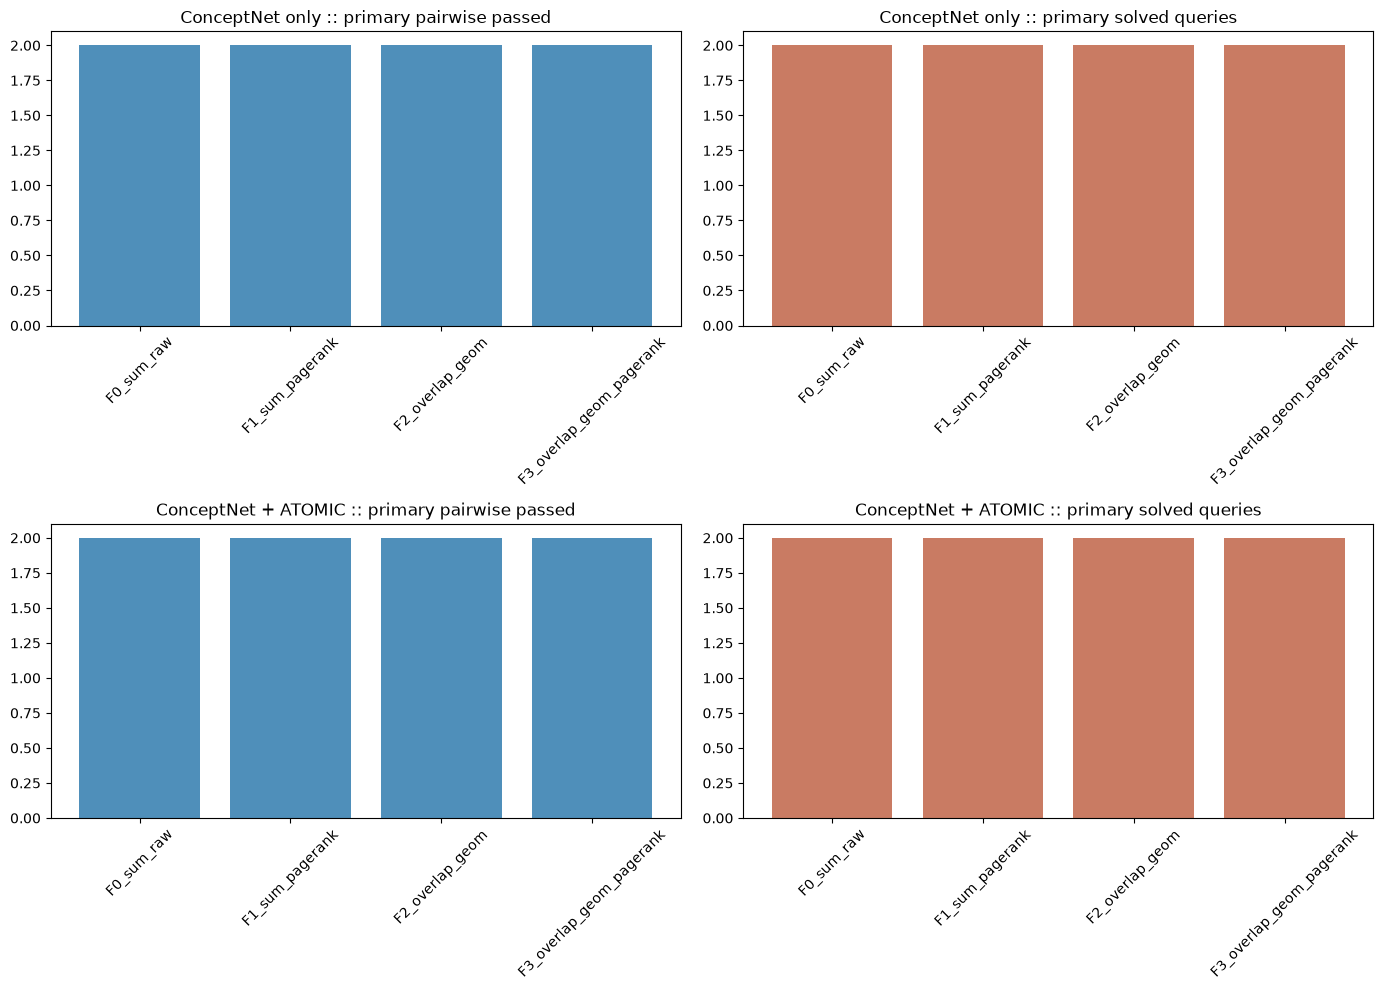

In [14]:
if plt is not None:
    fig, axes = plt.subplots(len(runs), 2, figsize=(14, 5 * max(1, len(runs))))
    if len(runs) == 1:
        axes = [axes]
    for row_idx, (variant_name, bundle) in enumerate(runs.items()):
        method_names = list(bundle['methods'].keys())
        pairwise_passed = [bundle['methods'][name]['summary']['primary']['pairwise_passed'] for name in method_names]
        solved_queries = [bundle['methods'][name]['summary']['primary']['solved_queries'] for name in method_names]
        axes[row_idx][0].bar(method_names, pairwise_passed, color='#4f8fba')
        axes[row_idx][0].set_title(f"{bundle['variant']['label']} :: primary pairwise passed")
        axes[row_idx][0].tick_params(axis='x', rotation=45)
        axes[row_idx][1].bar(method_names, solved_queries, color='#c97b63')
        axes[row_idx][1].set_title(f"{bundle['variant']['label']} :: primary solved queries")
        axes[row_idx][1].tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print('matplotlib unavailable; skipping plots.')


## Interpretation checklist

1. Does overlap improve `primary_pairwise` over sum-based aggregation?
2. Does overlap make the target visible because multiple cue-fields meet, rather than because one hub is bright?
3. After adding PageRank on top of overlap, is the effect helpful or over-corrective?
4. Do the control queries survive, or does overlap become too narrow?
5. If overlap still fails, is the next bottleneck path structure rather than final scoring?
